# Replicate correlation of the bulk profiles

Measures how well the replicate wells of each cell line agree, with the pairwise Pearson correlation between their bulk profiles.

**Why:** if the replicate wells of a cell line are similar, a profile reflects the cell line and not noise in one well.
A shuffled-feature baseline shows what a correlation of unrelated profiles looks like.

**Input:** `<plate>_bulk_feature_selected.parquet` of each plate (multivariate: the features selected for that plate).
Each plate has its own features, so correlations are computed within a plate.

**Extreme features** are removed first: a feature with an absolute value above `outlier_cutoff` in any well of the plate.
Some features have a near-zero MAD on a plate, so normalization gives values up to about 1e19, and one such feature would decide the correlation of two profiles on its own.
The pooled bulk profiles (`4.preprocess_features/3b.pooled_bulk_processing.ipynb`) remove the same features with the same cutoff.

**Replicates** are the wells of one plate with the same cell line, seeding density, and plate coating.
Most cell lines have four replicate wells, which gives six pairs.
The four wells of a cell line are neighbors on the plate (a 2x2 block), so they also share their position.

**Shuffled baseline:** for each pair, the order of the features of one well is shuffled and the correlation is computed again, repeated `n_shuffles` times.
The baseline is the average of these correlations and is near zero.

**Output:** in `results/`
- `replicate_correlation.csv`: one row per pair of replicate wells.
- `replicate_correlation_summary.csv`: one row per cell line and plate with the mean correlation over its pairs.

A pair row has the plate, time point, cell line, seeding density, plate coating, the two wells, `pearson`, `shuffled_pearson`, and the cancer group and tissue site of the cell line.

The notebook also plots the correlations (a histogram against the baseline, and the mean correlation of each cell line); the plot is shown in the notebook and is not saved to disk.

## Import libraries

In [1]:
import itertools
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.patches import Patch

## Set paths and parameters

In [2]:
metadata_path = pathlib.Path("../cell_lines/pccma_cell_line_metadata.csv")
groups_path = pathlib.Path("../cell_lines/plotting_helpers/cancer_type_categories.yaml")

# per-plate bulk feature-selected profiles: use the local data folder and fall back to the bandicoot mount
local_dir = pathlib.Path("../4.preprocess_features/data/bulk_profiles")
bandicoot_dir = pathlib.Path("~/mnt/bandicoot/PCCMA_data/Atlas_v2_profiles/bulk_profiles").expanduser()
profile_dir = local_dir if any(local_dir.glob("BR*_bulk_feature_selected.parquet")) else bandicoot_dir

results_dir = pathlib.Path("./results")
results_dir.mkdir(exist_ok=True)

replicate_columns = ["Metadata_cell_line", "Metadata_seeding_density", "Metadata_plate_coating"]  # within a plate
outlier_cutoff = 1000  # features above this absolute value in any well are removed (near-zero MAD artifacts)
n_shuffles = 100  # feature shuffles per pair for the baseline
rng = np.random.default_rng(0)

## Helper functions

In [3]:
def load_cell_line_groups(metadata_path, groups_path):
    """One row per cell line with its cancer type, cancer group and tissue site.

    The cancer groups and tissue sites come from cancer_type_categories.yaml, which lists
    which `cancer_type` values of the metadata belong to each group.
    """
    metadata = pd.read_csv(metadata_path).drop_duplicates("cell_line")  # U2-OS has one row per plate condition
    categories = yaml.safe_load(open(groups_path))
    groups = pd.DataFrame(
        [
            (cancer_type, group["name"], site["name"])
            for site in categories["sites"]
            for group in site["groups"]
            for cancer_type in group["cancer_types"]
        ],
        columns=["cancer_type", "cancer_group", "tissue_site"],
    )
    return metadata[["cell_line", "cancer_type", "origin"]].merge(groups, on="cancer_type", how="left")

In [4]:
def pairwise_pearson(profiles, n_shuffles, rng):
    """Pearson correlation of every pair of rows of `profiles`, and the mean correlation after shuffling the features of one row."""
    z = (profiles - profiles.mean(axis=1, keepdims=True)) / profiles.std(axis=1, keepdims=True)
    n_features = z.shape[1]
    pairs = []
    for i, j in itertools.combinations(range(len(z)), 2):
        observed = z[i] @ z[j] / n_features
        shuffled = np.mean([z[i] @ z[j][rng.permutation(n_features)] / n_features for _ in range(n_shuffles)])
        pairs.append((i, j, observed, shuffled))
    return pairs

## Correlation between replicate wells

One plate at a time.

In [5]:
rows = []
for plate_file in sorted(profile_dir.glob("BR*_bulk_feature_selected.parquet")):
    plate_df = pd.read_parquet(plate_file)
    features = [col for col in plate_df.columns if not col.startswith("Metadata_")]
    extreme = [col for col in features if plate_df[col].abs().max() > outlier_cutoff]
    features = [col for col in features if col not in extreme]
    print(f"{plate_df['Metadata_Plate'].iloc[0]}: {len(features)} features ({len(extreme)} removed for values above {outlier_cutoff})")

    for group_values, group_df in plate_df.groupby(replicate_columns):
        for i, j, observed, shuffled in pairwise_pearson(group_df[features].to_numpy(dtype=float), n_shuffles, rng):
            rows.append({
                "plate": group_df["Metadata_Plate"].iloc[0],
                "time_point": group_df["Metadata_time_point"].iloc[0],
                "cell_line": group_values[0],
                "seeding_density": group_values[1],
                "plate_coating": group_values[2],
                "well_a": group_df["Metadata_Well"].iloc[i],
                "well_b": group_df["Metadata_Well"].iloc[j],
                "pearson": observed,
                "shuffled_pearson": shuffled,
                "n_features": len(features),
            })

pairs_df = pd.DataFrame(rows).merge(
    load_cell_line_groups(metadata_path, groups_path)[["cell_line", "cancer_group", "tissue_site"]], on="cell_line", how="left"
)
assert pairs_df["cancer_group"].notna().all(), "a cell line has no cancer group"
pairs_df.to_csv(results_dir / "replicate_correlation.csv", index=False)
print(f"{len(pairs_df)} pairs of replicate wells from {pairs_df['plate'].nunique()} plates and {pairs_df['cell_line'].nunique()} cell lines")

BR00150695: 322 features (1 removed for values above 1000)
BR00150696: 337 features (1 removed for values above 1000)


BR00150697: 339 features (1 removed for values above 1000)


BR00150698: 381 features (1 removed for values above 1000)


BR00150699: 386 features (1 removed for values above 1000)


BR00150700: 372 features (1 removed for values above 1000)


BR00150701: 309 features (0 removed for values above 1000)


BR00150702: 292 features (0 removed for values above 1000)


BR00150703: 263 features (0 removed for values above 1000)
1068 pairs of replicate wells from 9 plates and 54 cell lines


## Summary per cell line and plate

In [6]:
summary_df = (
    pairs_df.groupby(["cell_line", "plate", "time_point", "seeding_density", "plate_coating", "cancer_group", "tissue_site"])
    .agg(n_pairs=("pearson", "size"), pearson=("pearson", "mean"), shuffled_pearson=("shuffled_pearson", "mean"))
    .reset_index()
)
summary_df.to_csv(results_dir / "replicate_correlation_summary.csv", index=False)

print("Mean replicate correlation per cell line, by time point (median over cell lines, and range):")
print(summary_df.groupby("time_point")["pearson"].agg(["median", "min", "max"]).round(2).to_string())
print(f"\nShuffled baseline: median {summary_df['shuffled_pearson'].median():.3f}, largest {summary_df['shuffled_pearson'].abs().max():.3f}")
print(f"Pairs with a correlation above 0.5: {(pairs_df['pearson'] > 0.5).mean():.1%}")

lowest = summary_df.nsmallest(5, "pearson")[["cell_line", "time_point", "pearson"]]
print("\nLowest replicate correlations:")
print(lowest.round(2).to_string(index=False))

Mean replicate correlation per cell line, by time point (median over cell lines, and range):
            median   min   max
time_point                    
24            0.87  0.52  0.99
48            0.86  0.44  0.99
72            0.87  0.31  0.98

Shuffled baseline: median -0.000, largest 0.007
Pairs with a correlation above 0.5: 96.4%

Lowest replicate correlations:
cell_line  time_point  pearson
  CHLA194          72     0.31
  CHLA196          48     0.44
  CHLA210          24     0.52
    U2-OS          24     0.58
  CHLA186          48     0.59


## Replicate correlation at a glance

Left, the correlation of all pairs of replicate wells against the shuffled-feature baseline.
Right, the mean correlation of each cell line (dot) and its range over the plates (line), colored by tissue site.
The cell lines with the lowest replicate correlation are on top.
The plot is displayed here and not saved to disk.

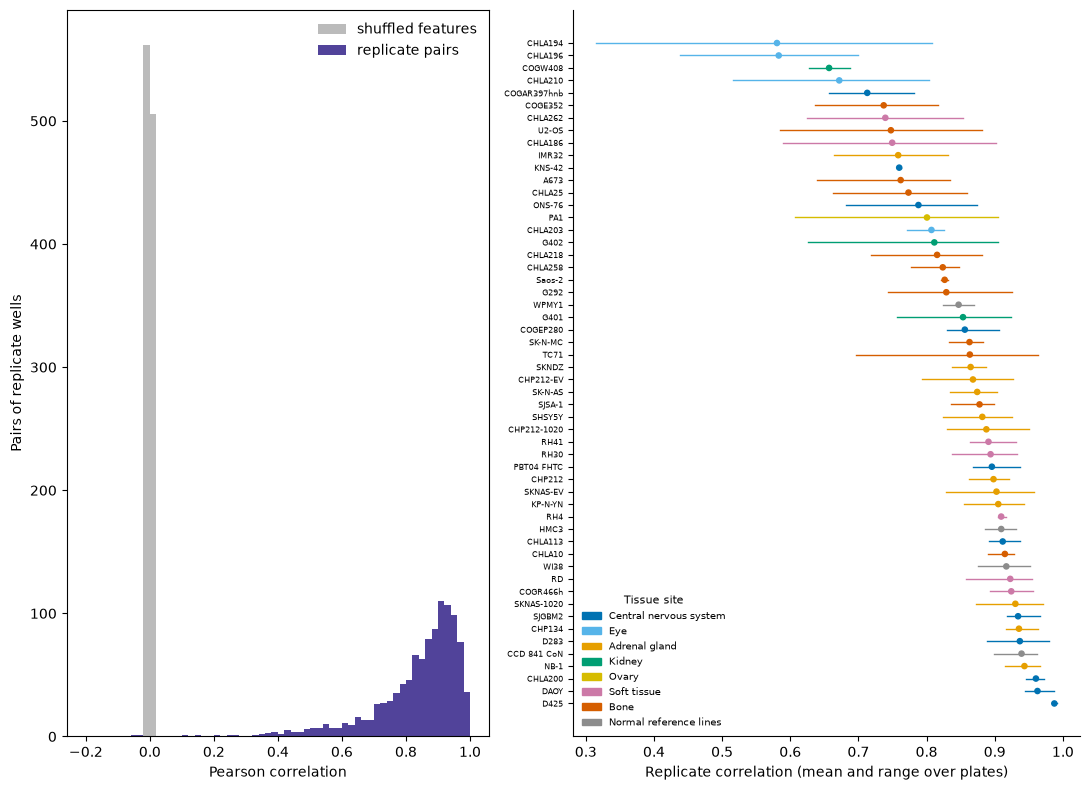

In [7]:
# tissue site colors, the same as `site_colors` in themes.R (in the order of the body, head to toe)
site_colors = {
    "Central nervous system": "#0072B2",
    "Eye": "#56B4E9",
    "Adrenal gland": "#E69F00",
    "Kidney": "#009E73",
    "Ovary": "#D6BC00",
    "Soft tissue": "#CC79A7",
    "Bone": "#D55E00",
    "Normal reference lines": "#8C8C8C",
}

fig, (hist_ax, line_ax) = plt.subplots(1, 2, figsize=(11, 8), gridspec_kw={"width_ratios": [1, 1.2]})

bins = np.linspace(-0.2, 1, 61)
hist_ax.hist(pairs_df["shuffled_pearson"], bins=bins, color="#BBBBBB", label="shuffled features")
hist_ax.hist(pairs_df["pearson"], bins=bins, color="#332288", alpha=0.85, label="replicate pairs")
hist_ax.set(xlabel="Pearson correlation", ylabel="Pairs of replicate wells")
hist_ax.legend(frameon=False)

per_line = (
    summary_df.groupby(["cell_line", "tissue_site"])["pearson"].agg(mean="mean", low="min", high="max").reset_index()
    .sort_values("mean").reset_index(drop=True)
)
for row in per_line.itertuples():
    line_ax.plot([row.low, row.high], [row.Index, row.Index], color=site_colors[row.tissue_site], lw=1)
line_ax.scatter(per_line["mean"], per_line.index, c=per_line["tissue_site"].map(site_colors), s=14, zorder=3)
line_ax.set_yticks(per_line.index, per_line["cell_line"], fontsize=6)
line_ax.invert_yaxis()
line_ax.set_xlabel("Replicate correlation (mean and range over plates)")
line_ax.spines[["top", "right"]].set_visible(False)
line_ax.legend(
    handles=[Patch(color=color, label=site) for site, color in site_colors.items() if site in set(per_line["tissue_site"])],
    title="Tissue site", fontsize=7, title_fontsize=8, frameon=False, loc="lower left",
)
fig.tight_layout()
plt.show()